# Ejercicios de práctica del primer parcial
Solución a la lista de ejercicios a programar para la materia de Simulación II, con el profesor Salat Figols, en el grupo 8MV1.

## Ejercicio 1
---

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import uniform, kstest
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.sandbox.stats.runs import runstest_1samp
# Función para generar números con el método LCG
def generador_lcg(x0, m, a, c, n):
    x = x0
    lista = [x / m] # Normalizamos el primer valor
    for i in range(n - 1):
        x = (a * x + c) % m
        lista.append(x / m)
    return np.array(lista)

# Parámetros dados en el ejercicio
m = 2**31
a = 1103515245
c = 12345
x0 = 174317
n = 10000

# Generamos los datos
datos = generador_lcg(x0, m, a, c, n)

# 1. Prueba de Bondad de Ajuste (Kolmogorov-Smirnov)
# Ajustamos una uniforme a los datos para obtener sus parámetros (loc, scale)
parametros = uniform.fit(datos) 
# Comparamos los datos con una distribución uniforme
ks_stat, p_valor_ks = kstest(datos, 'uniform', args=parametros)
print(f"Prueba KS: Estadístico={ks_stat:.4f}, p-valor={p_valor_ks:.5e}")
if p_valor_ks > 0.05:
    print("-> No se rechaza la uniformidad")

# 2. Prueba de Rachas (Runs Test)
# Evalúa si la secuencia es aleatoria basándose en valores por encima/debajo de la media
rachas_stat, p_valor_rachas = runstest_1samp(datos, cutoff='mean', correction=False)
print(f"\nPrueba de Rachas: Estadístico={rachas_stat:.4f}, p-valor={p_valor_rachas:.5e}")
if p_valor_rachas > 0.05:
    print("-> No se rechaza la aleatoriedad (Rachas esperadas).")

# 3. Prueba de Autocorrelación (Ljung-Box)
# Verifica si hay correlación con los valores pasados (lags)
autocorr_df = acorr_ljungbox(datos, lags=[1, 2, 3, 4, 5], return_df=True)
print("\nPrueba de Autocorrelación (Ljung-Box):")
print(autocorr_df[['lb_stat', 'lb_pvalue']])
# Si lb_pvalue > 0.05, no hay autocorrelación significativa.


Prueba KS: Estadístico=0.0077, p-valor=5.93653e-01
-> No se rechaza la uniformidad

Prueba de Rachas: Estadístico=0.9402, p-valor=3.47092e-01
-> No se rechaza la aleatoriedad (Rachas esperadas).

Prueba de Autocorrelación (Ljung-Box):
    lb_stat  lb_pvalue
1  0.351724   0.553139
2  0.919226   0.631528
3  2.007928   0.570763
4  2.618892   0.623480
5  4.637087   0.461754


### Gráfica
---

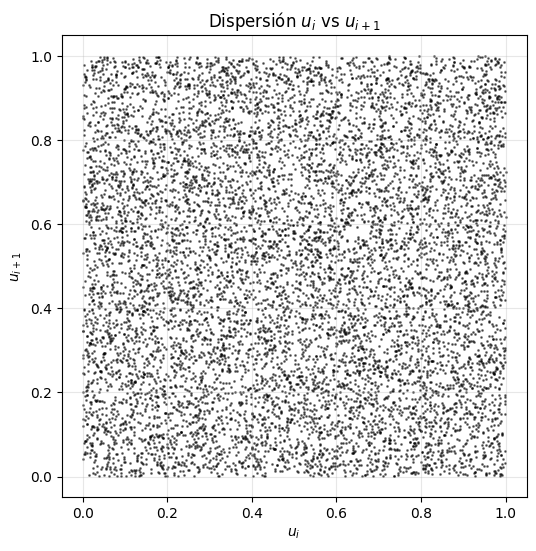

In [5]:
# 4. Gráfico de Dispersión (Visualización de Independencia)
# Graficamos u_i vs u_{i+1}. Debe verse como una nube sin patrones.
plt.figure(figsize=(6,6))
plt.scatter(datos[:-1], datos[1:], s=1, color='black', alpha=0.5)
plt.title('Dispersión $u_i$ vs $u_{i+1}$')
plt.xlabel('$u_i$'); plt.ylabel('$u_{i+1}$')
plt.grid(True, alpha=0.3)
plt.show()

## Ejercicio 2
---

### Inciso A
---

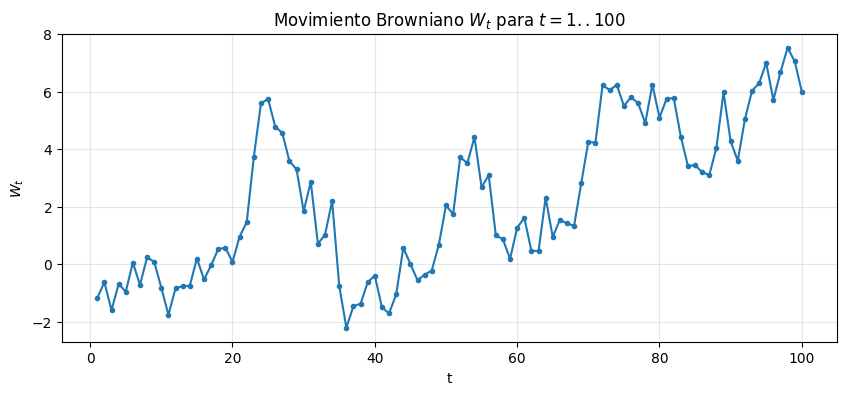

In [6]:
# --- EJERCICIO 2: Simulación de Movimiento Browniano ---
# a) Para t = 1, 2, ..., 100 (dt = 1)
n_pasos_a = 100
dt_a = 1
dW_a = np.random.normal(0, np.sqrt(dt_a), n_pasos_a)
W_a = np.cumsum(dW_a) # Suma acumulada de los incrementos

plt.figure(figsize=(10, 4))
plt.plot(range(1, n_pasos_a+1), W_a, marker='o', markersize=3)
plt.title('Movimiento Browniano $W_t$ para $t=1..100$')
plt.xlabel('t'); plt.ylabel('$W_t$'); plt.grid(True, alpha=0.3)
plt.show()

### Inciso B
---

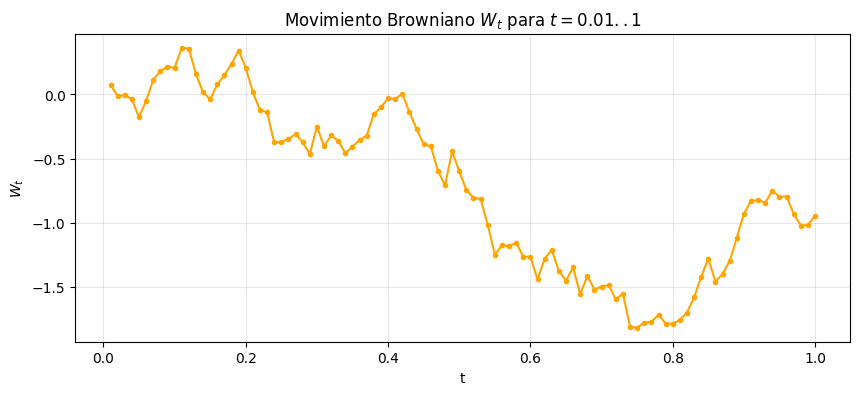

In [7]:
# b) Para t = 0.01, 0.02, ..., 1 (dt = 0.01)
n_pasos_b = 100
dt_b = 0.01
dW_b = np.random.normal(0, np.sqrt(dt_b), n_pasos_b)
W_b = np.cumsum(dW_b)
t_b = np.arange(dt_b, 1 + dt_b, dt_b)

plt.figure(figsize=(10, 4))
plt.plot(t_b, W_b, marker='o', markersize=3, color='orange')
plt.title('Movimiento Browniano $W_t$ para $t=0.01..1$')
plt.xlabel('t'); plt.ylabel('$W_t$'); plt.grid(True, alpha=0.3)
plt.show()

### Inciso C
---

In [8]:
# c) Estimar E[W_t^2] para t = 1, 0.1, 0.01, 0.001
# Simulamos N trayectorias y promediamos W_t^2
N = 100000
t_valores = [1, 0.1, 0.01, 0.001]
print("--- Estimación de E[W_t^2] ---")
for t in t_valores:
    # Simulamos N trayectorias hasta el tiempo t
    W_t = np.random.normal(0, np.sqrt(t), N)
    E_W2 = np.mean(W_t**2)
    print(f"t = {t:<6} -> E[W_t^2] ≈ {E_W2:.6f} (Teórico = {t})")



--- Estimación de E[W_t^2] ---
t = 1      -> E[W_t^2] ≈ 0.999134 (Teórico = 1)
t = 0.1    -> E[W_t^2] ≈ 0.100103 (Teórico = 0.1)
t = 0.01   -> E[W_t^2] ≈ 0.009939 (Teórico = 0.01)
t = 0.001  -> E[W_t^2] ≈ 0.001000 (Teórico = 0.001)


## Ejercicio 3
---

In [9]:
# --- EJERCICIO 3: Verificación por Simulación de la Integral de Itô ---
# Queremos verificar: int_0^t W_s dW_s = W_t^2/2 - t/2
t_final = 1.0
n_pasos_int = 10000
dt_int = t_final / n_pasos_int

# Simulamos una trayectoria
dW_int = np.random.normal(0, np.sqrt(dt_int), n_pasos_int)
W_int = np.concatenate(([0], np.cumsum(dW_int))) # W_0 = 0

# Aproximación numérica de la integral: sum(W_{t_i} * (W_{t_{i+1}} - W_{t_i}))
integral_sim = np.sum(W_int[:-1] * dW_int)
# Valor teórico: W_t^2/2 - t/2
valor_teorico = (W_int[-1]**2) / 2 - t_final / 2

print(f"\n--- Verificación Integral de Itô ---")
print(f"Integral simulada: {integral_sim:.6f}")
print(f"Valor teórico:     {valor_teorico:.6f}")
print(f"Diferencia:        {abs(integral_sim - valor_teorico):.6e}")


--- Verificación Integral de Itô ---
Integral simulada: -0.333982
Valor teórico:     -0.333075
Diferencia:        9.066829e-04


## Ejercicio 5
---

### Inciso A
---

In [10]:
# --- EJERCICIO 5: Movimiento Browniano Geométrico ---
# Parámetros
mu = 0.002
sigma = 0.01
P0 = 5.2
N_sim = 100000 # Número de simulaciones
T_dias = 30
dt = 1 # Paso diario

# Simulamos los incrementos W_t para 30 días
dW = np.random.normal(0, np.sqrt(dt), size=(N_sim, T_dias))
W = np.cumsum(dW, axis=1)

# Calculamos P_t para cada día t=1..30
# P_t = P0 * exp((mu - sigma^2/2)*t + sigma*W_t)
t_array = np.arange(1, T_dias + 1)
P_t = P0 * np.exp((mu - sigma**2/2) * t_array + sigma * W)

# a) E[P_20]
P20 = P_t[:, 19] # Índice 19 corresponde al día 20
E_P20_sim = np.mean(P20)
E_P20_teorico = P0 * np.exp(mu * 20)
error_P20 = abs(E_P20_sim - E_P20_teorico) / E_P20_teorico * 100
print(f"a) E[P_20] Simulado: {E_P20_sim:.4f} | Teórico: {E_P20_teorico:.4f} | Error: {error_P20:.4f}%")

a) E[P_20] Simulado: 5.4113 | Teórico: 5.4122 | Error: 0.0177%


### Inciso B
---

In [13]:
# b) P(P_30 > 10.4)
P30 = P_t[:, 29]
prob_sim = np.mean(P30 > 10.4)
# Teórico aproximado usando lognormal
from scipy.stats import norm
d = (np.log(10.4/P0) - (mu - sigma**2/2)*30) / (sigma * np.sqrt(30))
prob_teorica = 1 - norm.cdf(d)
print(f"b) P(P_30 > 10.4) Simulado: {prob_sim:.2e} | Teórico: {prob_teorica:.2e}")


b) P(P_30 > 10.4) Simulado: 0.00e+00 | Teórico: 0.00e+00


### Inciso C
---

In [14]:
# c) Días esperados para superar 10.4
# Buscamos el primer índice donde P_t > 10.4
dias_superacion = np.argmax(P_t > 10.4, axis=1) + 1
# Si nunca supera 10.4, argmax devuelve 0, lo tratamos como NaN
dias_superacion = np.where(P_t.max(axis=1) > 10.4, dias_superacion, np.nan)
E_dias = np.nanmean(dias_superacion)
print(f"c) Días esperados para superar 10.4: {E_dias:.2f} días")


c) Días esperados para superar 10.4: nan días


/tmp/ipykernel_3667/2779799051.py:6: RuntimeWarning: Mean of empty slice
  E_dias = np.nanmean(dias_superacion)


### Inciso D
---

In [15]:
# d) Máximo esperado de P_0...P_10
P_0_10 = np.column_stack((np.full(N_sim, P0), P_t[:, :10]))
maximos = np.max(P_0_10, axis=1)
E_max = np.mean(maximos)
print(f"d) E[Máximo de P_0 a P_10]: {E_max:.4f}")

d) E[Máximo de P_0 a P_10]: 5.3672


## Ejercicio 6
---

### Inciso A
---

In [16]:
# --- EJERCICIO 6: Movimientos Brownianos Correlacionados ---
r = 0.5
t1, t2 = 10, 15
# a) Encontrar a, b, c
# a = sqrt(t1), b = r*sqrt(t1), c = sqrt(t1*(1-r^2))
a = np.sqrt(t1)
b = r * np.sqrt(t1)
c = np.sqrt(t1 * (1 - r**2))
# Nota: Para W_t2, la varianza debe ser t2. 
# Usaremos W_t2 = r*sqrt(t2)*Z1 + sqrt(t2*(1-r^2))*Z2
a2 = np.sqrt(t2)
b2 = r * np.sqrt(t2)
c2 = np.sqrt(t2 * (1 - r**2))

Z1 = np.random.normal(0, 1, N_sim)
Z2 = np.random.normal(0, 1, N_sim)
W10_1 = a * Z1
W15_2 = b2 * Z1 + c2 * Z2

### Inciso B
---

In [17]:
# b) E[2e^(0.01 W10_1) + 3e^(0.003 W15_2)]
expresion = 2 * np.exp(0.01 * W10_1) + 3 * np.exp(0.003 * W15_2)
E_expresion = np.mean(expresion)
print(f"\n6b) E[2e^(0.01W10_1) + 3e^(0.003W15_2)] = {E_expresion:.4f}")


6b) E[2e^(0.01W10_1) + 3e^(0.003W15_2)] = 5.0011


##  Ejercicio 7
---

/tmp/ipykernel_3667/477785973.py:11: FutureWarning: YF.download() has changed argument auto_adjust default to True
  datos = yf.download(ticker, period='100d', interval='1d')
[*********************100%***********************]  1 of 1 completed


Datos de AAPL descargados correctamente.

--- Parámetros Estimados por MLE ---
mu_log (diario): 0.001137, sigma (diario): 0.017814
Parámetros GBM anualizados: mu = 0.2868, sigma = 0.2828


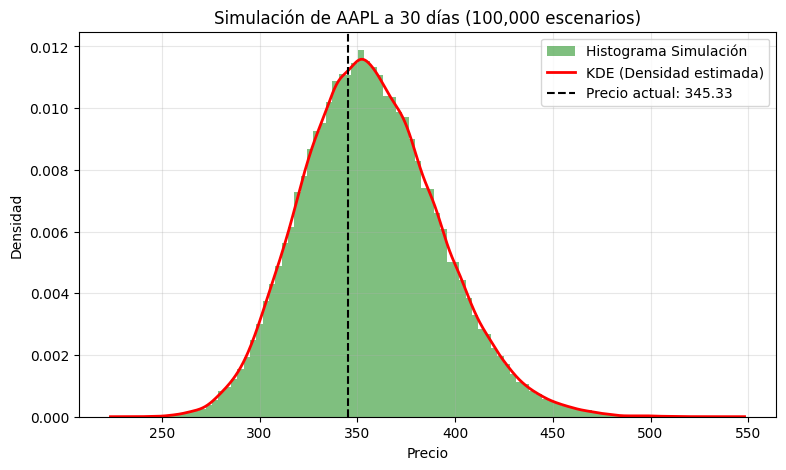

In [18]:
import yfinance as yf
from scipy.stats import norm, gaussian_kde
from scipy.optimize import minimize

# ==========================================
# 1. DESCARGA DE DATOS
# ==========================================
# Intentamos descargar 100 días de una acción (ej. Apple)
try:
    ticker = 'AAPL'
    datos = yf.download(ticker, period='100d', interval='1d')
    precios = datos['Close'].values.flatten()
    print(f"Datos de {ticker} descargados correctamente.")
except Exception as e:
    # En caso de fallo de red, generamos datos sintéticos para que el código corra
    print("Fallo en la descarga. Usando datos sintéticos...")
    precios = 100 * np.exp(np.cumsum(np.random.normal(0.0005, 0.02, 100)))

# ==========================================
# 2. CÁLCULO DE LOG-RETORNOS Y MLE
# ==========================================
# Calculamos los log-retornos diarios
log_retornos = np.diff(np.log(precios))
dt = 1 / 252  # Paso de tiempo diario (asumiendo 252 días hábiles al año)

# Función de Log-Verosimilitud Negativa
def log_verosimilitud_negativa(params, r):
    """
    Calcula -sum(log(f(r_t))) asumiendo que los log-retornos siguen una Normal.
    params: [mu_log, sigma]
    """
    mu_log, sigma = params[0], params[1]
    n = len(r)
    # Log-verosimilitud de una distribución Normal
    ll = -n/2 * np.log(2 * np.pi) - n * np.log(sigma) - np.sum((r - mu_log)**2) / (2 * sigma**2)
    return -ll

# Estimación por MLE usando optimización
# Punto de partida: media y desviación estándar de los log-retornos
x0 = [np.mean(log_retornos), np.std(log_retornos)]
res = minimize(log_verosimilitud_negativa, x0, args=(log_retornos,), method='Nelder-Mead')
mu_log_est, sigma_est = res.x

# Convertimos los parámetros a la escala anualizada del GBM
mu_est = mu_log_est / dt + (sigma_est**2) / 2
sigma_anual = sigma_est / np.sqrt(dt)

print(f"\n--- Parámetros Estimados por MLE ---")
print(f"mu_log (diario): {mu_log_est:.6f}, sigma (diario): {sigma_est:.6f}")
print(f"Parámetros GBM anualizados: mu = {mu_est:.4f}, sigma = {sigma_anual:.4f}")

# ==========================================
# 3. SIMULACIÓN A 30 DÍAS
# ==========================================
N_sim = 100000  # Número de simulaciones
T = 30 / 252    # 30 días en años
P0 = precios[-1] # Último precio observado

# Simulamos el movimiento browniano para 30 días
dW = np.random.normal(0, np.sqrt(dt), size=(N_sim, 30))
W_T = np.sum(dW, axis=1)

# Fórmula de GBM
P_T = P0 * np.exp((mu_est - (sigma_anual**2)/2) * T + sigma_anual * W_T)

# ==========================================
# 4. KDE Y GRÁFICO
# ==========================================
# Aplicamos KDE para suavizar el histograma de los precios simulados
kde = gaussian_kde(P_T)
x_vals = np.linspace(P_T.min(), P_T.max(), 1000)
pdf_vals = kde(x_vals)

plt.figure(figsize=(9, 5))
# Histograma de los precios simulados
plt.hist(P_T, bins=100, density=True, alpha=0.5, color='green', label='Histograma Simulación')
# Curva de densidad estimada por KDE
plt.plot(x_vals, pdf_vals, color='red', lw=2, label='KDE (Densidad estimada)')
# Línea del precio actual
plt.axvline(P0, color='black', linestyle='--', label=f'Precio actual: {P0:.2f}')

plt.title(f'Simulación de {ticker} a 30 días (100,000 escenarios)')
plt.xlabel('Precio')
plt.ylabel('Densidad')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Ejercicio 8
---

### Inciso A
---

In [19]:
# --- EJERCICIO 8: SDE dX_t = X_t dW_t ---
# a) Solución: X_t = X0 * exp(W_t - t/2)
X0 = 1
t_final = 10
# Simulamos W_10
W_10 = np.random.normal(0, np.sqrt(t_final), N_sim)
# Calculamos X_10
X_10 = X0 * np.exp(W_10 - t_final/2)

### Inciso B
---

In [20]:
# b) E[X_t] = X0
print(f"\n8b) E[X_10] Simulado: {np.mean(X_10):.4f} | Teórico: {X0}")


8b) E[X_10] Simulado: 1.0392 | Teórico: 1


### Inciso C
---

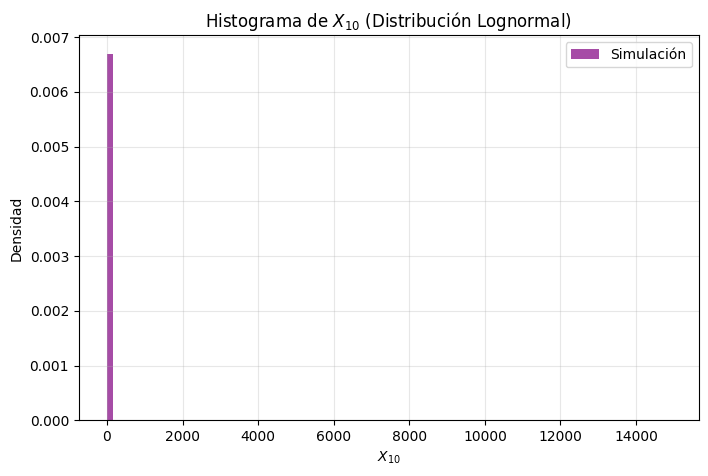

In [21]:
# c) Histograma de X_10
plt.figure(figsize=(8, 5))
plt.hist(X_10, bins=100, density=True, alpha=0.7, color='purple', label='Simulación')
plt.title('Histograma de $X_{10}$ (Distribución Lognormal)')
plt.xlabel('$X_{10}$'); plt.ylabel('Densidad')
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()
# d) ¿Qué distribución sigue? -> Lognormal, porque es la exponencial de una Normal.